# EXP-006 — MLP baseline mặc định

### Người thực hiện: Phạm Quỳnh Như
### Ngày tạo notebook: 13/11
### Loại thực nghiệm dự kiến: rerun — chạy lại bằng runner dùng chung
### Trạng thái: đang chuẩn bị chạy
Bài toán: Multiclass và Binary.




## Câu hỏi nghiên cứu và giả thuyết

### 1.Câu hỏi:MLP mặc định dự đoán ba trạng thái Baseline/Stress/Amusement và phân biệt Stress/Non-stress trên người chưa xuất hiện trong tập huấn luyện như thế nào?

### 2.Giả thuyết cần kiểm chứng: chất lượng dự đoán có thể khác nhau giữa các lớp và giữa các subject , điểm nhị phân cao chưa chắc đi kèm khả năng phân biệt tốt cả ba trạng thái.



## 1.Dữ liệu và kiểm tra môi trường

Dùng bộ physiological68, 68 feature , ghi đường dẫn, schema, số dòng, subject, target và SHA-256 thực tế sau khi kiểm tra.




In [1]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import hashlib
import json

ROOT = Path(
    r"C:\Users\LEGION\Desktop\github\Machine-learning"
    r"\wesad-stress-detection"
)

DATA = ROOT / "data/features/g2_physiological68_group15_20261107/all_subjects.csv"
SCHEMA = DATA.parent / "feature_schema.json"

print("Thời điểm kiểm tra:",
      datetime.now(timezone(timedelta(hours=7))).isoformat())

assert DATA.is_file(), f"Không tìm thấy dữ liệu: {DATA}"
assert SCHEMA.is_file(), f"Không tìm thấy schema: {SCHEMA}"

schema = json.loads(SCHEMA.read_text(encoding="utf-8"))
features = schema["feature_columns"]
assert len(features) == 68, "Số feature không đúng 68."

checksum = hashlib.sha256(DATA.read_bytes()).hexdigest()
expected = "2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba"
assert checksum == expected, "Dữ liệu khác bộ đã thống nhất."

print("Số feature:", len(features))
print("SHA-256:", checksum)
print("Kiểm tra đầu vào đạt. Chưa huấn luyện mô hình.")

Thời điểm kiểm tra: 2026-11-13T22:29:47.196873+07:00
Số feature: 68
SHA-256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
Kiểm tra đầu vào đạt. Chưa huấn luyện mô hình.


In [2]:
import pandas as pd
from IPython.display import display

frame = pd.read_csv(
    DATA,
    dtype={"subject_id": str, "window_id": str}
)

# Kiểm tra cấu trúc cơ bản.
assert frame["subject_id"].nunique() == 15
assert frame["label_original"].isin([1, 2, 3]).all()
assert not frame.duplicated(["subject_id", "window_id"]).any()

print("Số dòng dữ liệu:", len(frame))
print("Tổng số cột:", len(frame.columns))
print("Số cột feature:", len(features))
print("Số subject:", frame["subject_id"].nunique())

# Đếm số mẫu thuộc từng lớp của mỗi người.
distribution = pd.crosstab(
    frame["subject_id"],
    frame["label_original"]
).rename(columns={
    1: "Baseline",
    2: "Stress",
    3: "Amusement"
})

display(distribution)

# Kiểm tra cách chia cho lượt quick S4.
train_mask = frame["subject_id"] != "S4"
test_mask = frame["subject_id"] == "S4"

print("Số người train:",
      frame.loc[train_mask, "subject_id"].nunique())
print("Số người test:",
      frame.loc[test_mask, "subject_id"].nunique())
print("Số mẫu train:", int(train_mask.sum()))
print("Số mẫu test:", int(test_mask.sum()))

missing = frame[features].isna().sum().sum()
print("Số ô feature bị thiếu:", int(missing))

Số dòng dữ liệu: 6189
Tổng số cột: 76
Số cột feature: 68
Số subject: 15


label_original,Baseline,Stress,Amusement
subject_id,,,
S10,226,135,65
S11,227,126,64
S13,226,124,67
S14,219,126,65
S15,226,128,64
S16,226,125,64
S17,226,135,65
S2,219,113,63
S3,218,118,65


Số người train: 14
Số người test: 1
Số mẫu train: 5785
Số mẫu test: 404
Số ô feature bị thiếu: 37460


### nhận xét dữ liêu (13/11)
15 subject đều có cả 3 lớp nhưng phân bố không được cân bằng => không nên chỉ dựa vào accuracy 

s4 được làm test với 404 mẫu : 222 baseline , 117 stress và 65 amusement 

tập train 5785 mẫu là thuộc về 14 người còn lại

feature vẫn còn thiếu 37460 ô => sẽ xử lí sau 

=> tạm thời đã thực hiện kiểm tra cấu trúc nhưng vẫn cần lưu ý những hạn chế chưa được xử lí nên bước này vẫn chưa đánh giá được chất lượng mlp

##   2.đánh giá protocol

sử dụng LOSO sử dụng 1 subject để làm test và để 14 subject còn lại làm train 

đánh giá đầy đủ sẽ lặp lại đủ 15 subject , mỗi người sẽ được làm test 1 lần 

chỉ gồm 68 feature theo schema

không tuning, feature selection hoặc balancing trong EXP-006

nếu đủ 15 người rồi thì tính trung bình và độ lệch chuẩn mẫu của điểm theo người 



## 3.Cấu hình

sử dụng pipeline dùng chung của project 

giữ tham số mặc định để train

chỉ đặt random_state = 42.

không tuning , balancing hoặc feature selection


In [3]:
import subprocess
import json
import pandas as pd
from IPython.display import display

TRAIN_PYTHON = ROOT / ".venv-g1/Scripts/python.exe"
assert TRAIN_PYTHON.is_file(), "Không tìm thấy Python dùng để train."

# Đọc pipeline bằng đúng môi trường train.
# Đoạn này chỉ tạo/kiểm tra cấu hình, không gọi fit().
inspect_code = """
import sys
import json
import sklearn
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))

from wesad.utils import read_config
from wesad.models import build_pipeline

config = read_config("configs/defaults.yaml")
config["models"] = ["mlp"]

pipeline = build_pipeline("mlp", config)

info = {
    "python": sys.version.split()[0],
    "sklearn": sklearn.__version__,
    "seed": config["seed"],
    "tasks": config["tasks"],
    "nested": config.get("nested", False),
    "balance": config.get("balance", False),
    "pipeline_steps": list(pipeline.named_steps),
    "imputer_strategy": pipeline["imputer"].strategy,
    "keep_empty_features": pipeline["imputer"].keep_empty_features,
    "mlp_parameters": pipeline["model"].get_params()
}

print(json.dumps(info))
"""

result = subprocess.run(
    [str(TRAIN_PYTHON), "-c", inspect_code],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=True,
)

config_info = json.loads(result.stdout)

print("Python dùng để train:", config_info["python"])
print("scikit-learn:", config_info["sklearn"])
print("Các bước pipeline:", config_info["pipeline_steps"])
print("Imputer:", config_info["imputer_strategy"])
print("Giữ cột bị thiếu toàn bộ trong train:",
      config_info["keep_empty_features"])
print("Các bài toán:", config_info["tasks"])
print("Tuning:", config_info["nested"])
print("Balancing:", config_info["balance"])

display(pd.DataFrame.from_dict(
    config_info["mlp_parameters"],
    orient="index",
    columns=["Giá trị thực tế"]
))

print("Đã đọc cấu hình. Chưa huấn luyện mô hình.")


Python dùng để train: 3.12.14
scikit-learn: 1.9.1
Các bước pipeline: ['imputer', 'scaler', 'model']
Imputer: median
Giữ cột bị thiếu toàn bộ trong train: True
Các bài toán: ['multiclass', 'binary']
Tuning: False
Balancing: False


,Giá trị thực tế
activation,relu
alpha,0.0001
batch_size,auto
beta_1,0.9
beta_2,0.999
early_stopping,False
epsilon,0.0
hidden_layer_sizes,[100]
learning_rate,constant
learning_rate_init,0.001


Đã đọc cấu hình. Chưa huấn luyện mô hình.


## 4.Thực thi


In [12]:
import json
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score

RUN_DEBUG = True # Đổi True để chạy thử MLP mặc định trên S4, False để chỉ kiểm tra cấu hình.

if RUN_DEBUG:
    frame = pd.read_csv(DATA)
    schema = json.loads(SCHEMA.read_text(encoding="utf-8"))
    features = schema["feature_columns"]

    train = frame["subject_id"] != "S4"
    test = frame["subject_id"] == "S4"

    X_train = frame.loc[train, features]
    y_train = frame.loc[train, "label_original"]
    X_test = frame.loc[test, features]
    y_test = frame.loc[test, "label_original"]

    debug_mlp = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True,
        )),
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(100,),
            activation="relu",
            max_iter=200,
            random_state=42,
        )),
    ])

    debug_mlp.fit(X_train, y_train)
    predicted = debug_mlp.predict(X_test)

    print("Macro-F1:", f1_score(
        y_test,
        predicted,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0,
    ))
else:
    print("Chưa chạy mlp . Đặt RUN_DEBUG=True để thực hiện.")

Macro-F1: 0.621225978366416


### nhận xét lỗi mlp(13/11)
chạy lần 1

hiện tượng : chương trình dừng tại bước fit() của MLP 

lí do : do giá trị activation="ReLU" không được chấp nhận , tên giá trị tham số phân biệt chữ hoa và chữ thường 

cách xử lí : sửa thành relu 

đã sửa và chạy lần 2 

kết quả sau khi chạy : chạy ra macro f1 


## 5. Kết quả trên s4

 phân tích mô hình đã huấn luyện ở mục 4 khỏi train lại 

In [13]:
import sys
import sklearn
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)

# Kiểm tra MLP đã được fit.
model = debug_mlp.named_steps["model"]
assert hasattr(model, "classes_"), "MLP chưa được huấn luyện."
assert X_test.index.equals(y_test.index)

# Chỉ dự đoán bằng mô hình đã fit, không train lại.
predicted = debug_mlp.predict(X_test)

labels = [1, 2, 3]
names = ["Baseline", "Stress", "Amusement"]

results = pd.DataFrame([{
    "model": "MLP",
    "task": "multiclass",
    "outer_test": "S4",
    "n_test": len(y_test),
    "macro_f1": f1_score(
        y_test, predicted,
        labels=labels, average="macro", zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, predicted
    ),
}])

print("BẢNG ĐIỂM NGOÀI MẪU")
display(results)

report = classification_report(
    y_test,
    predicted,
    labels=labels,
    target_names=names,
    output_dict=True,
    zero_division=0,
)

print("KẾT QUẢ TỪNG LỚP")
display(pd.DataFrame(report).T)

matrix = confusion_matrix(y_test, predicted, labels=labels)
cm_table = pd.DataFrame(
    matrix,
    index=[f"Thật: {name}" for name in names],
    columns=[f"Đoán: {name}" for name in names],
)

print("CONFUSION MATRIX")
display(cm_table)

print("Số epoch thực tế:", model.n_iter_)
print("Train loss cuối:", model.loss_)
print("Môi trường của lượt thử:",
      sys.version.split()[0], "| sklearn:", sklearn.__version__)

BẢNG ĐIỂM NGOÀI MẪU


,model,task,outer_test,n_test,macro_f1,balanced_accuracy
0,MLP,multiclass,S4,404,0.621226,0.660969


KẾT QUẢ TỪNG LỚP


,precision,recall,f1-score,support
Baseline,0.773519,1.000000,0.872299,222.000000
Stress,1.000000,0.982906,0.991379,117.000000
Amusement,0.000000,0.000000,0.000000,65.000000
accuracy,0.834158,0.834158,0.834158,0.834158
macro avg,0.591173,0.660969,0.621226,404.000000
weighted avg,0.714657,0.834158,0.766440,404.000000


CONFUSION MATRIX


,Đoán: Baseline,Đoán: Stress,Đoán: Amusement
Thật: Baseline,222,0,0
Thật: Stress,0,115,2
Thật: Amusement,65,0,0


Số epoch thực tế: 47
Train loss cuối: 0.0010124072111406227
Môi trường của lượt thử: 3.13.9 | sklearn: 1.7.2


### nhận xét (14/11)

MLP trên s4 chạy đạt 

macro f1 = 0,6212 | Balanced accuracy = 0,6610

Mô hình nhận đúng 222/222 mẫu Baseline, 115/117 mẫu Stress,
nhưng sai toàn bộ 65 mẫu Amusement.

Mô hình dừng ở 47 epoch, train loss khoảng 0,001012.
Loss thấp chưa đồng nghĩa dự đoán tốt trên test.

Đây mới là kết quả Multiclass của S4. Cần thống nhất
môi trường với mục 05 trước khi chốt baseline.

## 6. Hình minh họa




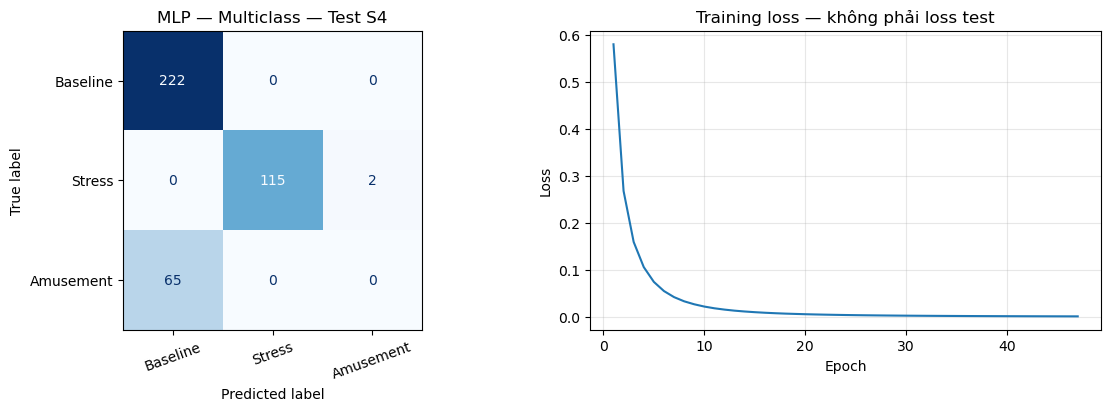

Đã lưu hình tại: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\EXP006_S4_figures_20261114_001616_483266


In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from datetime import datetime

model = debug_mlp.named_steps["model"]

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained"
)

ConfusionMatrixDisplay.from_predictions(
    y_test, predicted,
    labels=[1, 2, 3],
    display_labels=["Baseline", "Stress", "Amusement"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("MLP — Multiclass — Test S4")
axes[0].tick_params(axis="x", labelrotation=20)

loss = model.loss_curve_
axes[1].plot(range(1, len(loss) + 1), loss)
axes[1].set(
    title="Training loss — không phải loss test",
    xlabel="Epoch", ylabel="Loss"
)
axes[1].grid(alpha=0.3)

FIG_DIR = ROOT / "outputs" / (
    "EXP006_S4_figures_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
FIG_DIR.mkdir(parents=True)
fig.savefig(FIG_DIR / "confusion_matrix_and_loss.png", dpi=150)

plt.show()
print("Đã lưu hình tại:", FIG_DIR)

## 7. Phân tích

Accuracy khoảng gần 84% nhưng mô hình vẫn chưa nhận đúng mẫu amusement nào => không nên dựa vào accuracy để đánh giá chất lượng phân lớp 

khi kết quả test còn hạn chế mà lại train loss nên không thể kết luận sớm

kết quả này chỉ thuộc s4 

không tham tham số chỉ để cải thiện teat s4

## 8. Kết luận, provenance và nhật ký (14/11)

MLP đã chạy được sau khi sửa lỗi "ReLu" thành "relu" 

Vẫn còn hạn chế là chưa nhận diện đúng lớp amusement 

Nguồn kết quả: các ô thực thi và phân tích trong notebook này

Cấu hình: một lớp ẩn 100 nút, ReLU, max_iter=200, seed 42

Môi trường thực thi: Python 3.13.9, scikit-learn 1.7.2.

Dữ liệu: physiological68, đã kiểm tra SHA-256 
trạng thái lượt thử trên s4 => vẫn chưa hoàn thành exp006

Việc còn thiếu :

thống nhất môi trường 

bổ sung binary và đánh giá đủ loso 

so sánh với RF/SVM cùng điều kiện 

